In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import json
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [3]:
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

print("Folders ready.")

Folders ready.


In [4]:
df = pd.read_csv("Milk_Quality_Dataset.csv")
df.head()

,Quality_Grade,pH,Titratable_Acidity,Fat_Percentage,SNF_Percentage,Lactose,Protein,Density,Conductivity,Freezing_Point,Water_Adulteration_Percent,Urea,Detergent,Starch,Neutralizers,Preservatives,Antibiotics
0,Adulterated,7.02,0.156,3.58,8.17,4.278,3.217,1.0294,5.858,-0.461,34.1,1,0,0,1,0,0
1,Low Quality,6.72,0.157,2.86,7.78,4.527,3.079,1.0330,5.296,-0.496,4.7,0,0,0,0,0,0
2,High Quality,7.16,0.157,4.61,8.73,4.787,2.916,1.0265,5.018,-0.497,4.3,0,0,0,0,0,0
3,Low Quality,6.24,0.154,3.57,8.13,5.018,3.058,1.0264,3.940,-0.543,3.8,0,0,0,0,0,1
4,Low Quality,6.45,0.176,3.05,7.93,5.113,2.924,1.0312,4.692,-0.538,2.7,0,0,0,0,0,0


In [5]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (10000, 17)

Columns:
['Quality_Grade', 'pH', 'Titratable_Acidity', 'Fat_Percentage', 'SNF_Percentage', 'Lactose', 'Protein', 'Density', 'Conductivity', 'Freezing_Point', 'Water_Adulteration_Percent', 'Urea', 'Detergent', 'Starch', 'Neutralizers', 'Preservatives', 'Antibiotics']

Missing values:
Quality_Grade                 0
pH                            0
Titratable_Acidity            0
Fat_Percentage                0
SNF_Percentage                0
Lactose                       0
Protein                       0
Density                       0
Conductivity                  0
Freezing_Point                0
Water_Adulteration_Percent    0
Urea                          0
Detergent                     0
Starch                        0
Neutralizers                  0
Preservatives                 0
Antibiotics                   0
dtype: int64

Duplicate rows: 0


In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", df.shape)

Shape after duplicate removal: (10000, 17)


Quality_Grade
High Quality    3500
Adulterated     2500
Low Quality     2500
Spoiled         1500
Name: count, dtype: int64


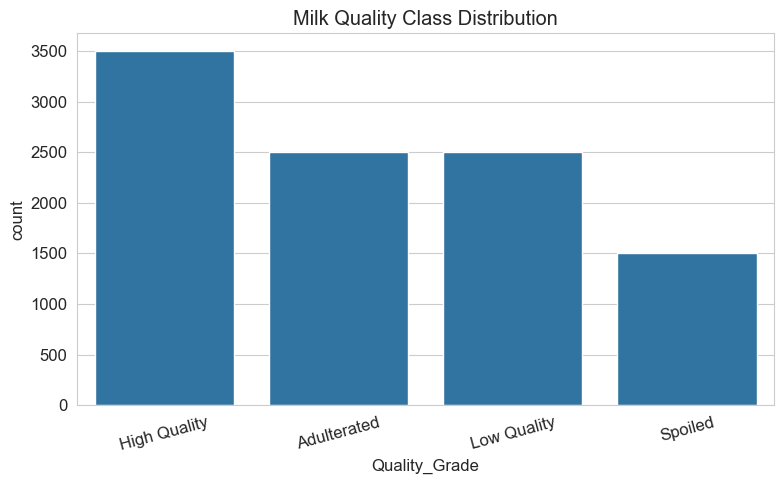

In [7]:
print(df["Quality_Grade"].value_counts())

plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Quality_Grade", order=df["Quality_Grade"].value_counts().index)
plt.title("Milk Quality Class Distribution")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("outputs/class_distribution.png", dpi=300)
plt.show()

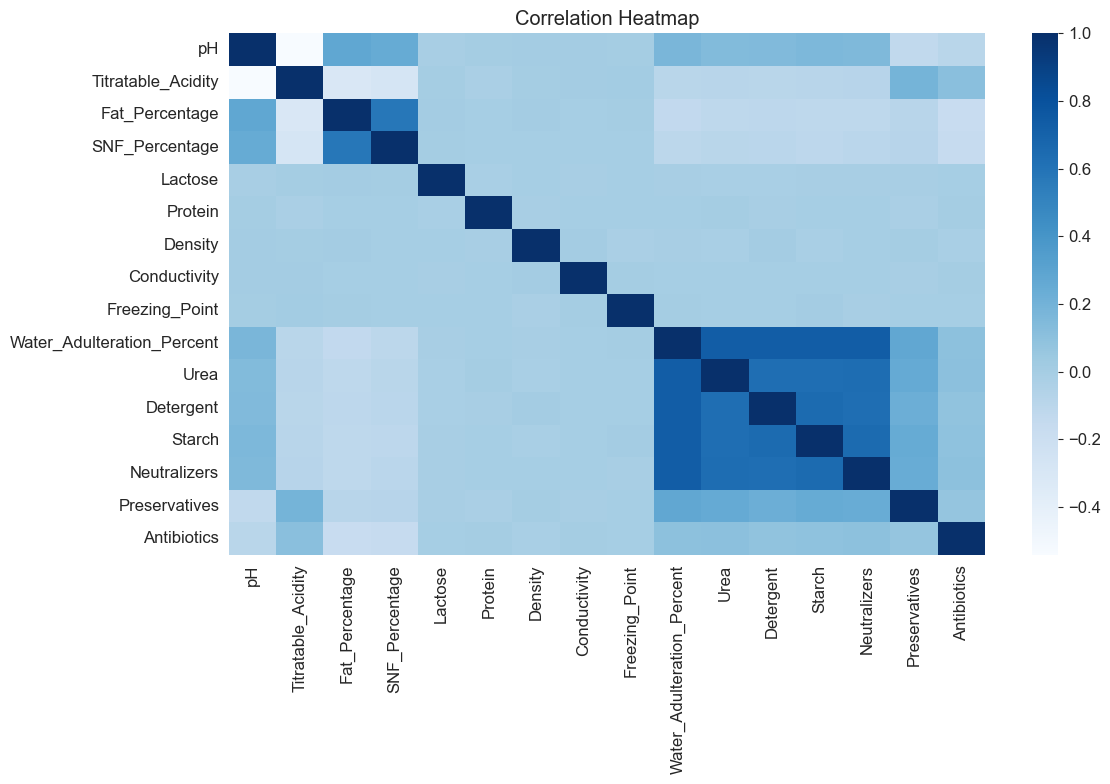

In [8]:
plt.figure(figsize=(12,8))
numeric_df = df.drop(columns=["Quality_Grade"])
corr = numeric_df.corr()
sns.heatmap(corr, cmap="Blues")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png", dpi=300)
plt.show()

In [9]:
all_features = [
    'pH',
    'Titratable_Acidity',
    'Fat_Percentage',
    'SNF_Percentage',
    'Lactose',
    'Protein',
    'Density',
    'Conductivity',
    'Freezing_Point',
    'Water_Adulteration_Percent',
    'Urea',
    'Detergent',
    'Starch',
    'Neutralizers',
    'Preservatives',
    'Antibiotics'
]

screening_features = [
    'pH',
    'Titratable_Acidity',
    'Fat_Percentage',
    'SNF_Percentage',
    'Lactose',
    'Protein',
    'Density',
    'Conductivity',
    'Freezing_Point'
]

target_col = "Quality_Grade"

print("All features:", all_features)
print("\nScreening model features:", screening_features)

All features: ['pH', 'Titratable_Acidity', 'Fat_Percentage', 'SNF_Percentage', 'Lactose', 'Protein', 'Density', 'Conductivity', 'Freezing_Point', 'Water_Adulteration_Percent', 'Urea', 'Detergent', 'Starch', 'Neutralizers', 'Preservatives', 'Antibiotics']

Screening model features: ['pH', 'Titratable_Acidity', 'Fat_Percentage', 'SNF_Percentage', 'Lactose', 'Protein', 'Density', 'Conductivity', 'Freezing_Point']


In [10]:
print("""
We are excluding:
- Water_Adulteration_Percent
- Urea
- Detergent
- Starch
- Neutralizers
- Preservatives
- Antibiotics

Reason:
These variables act like direct adulteration indicators and can make classification unrealistically easy.
The screening model should rely on intrinsic physicochemical properties only.
""")


We are excluding:
- Water_Adulteration_Percent
- Urea
- Detergent
- Starch
- Neutralizers
- Preservatives
- Antibiotics

Reason:
These variables act like direct adulteration indicators and can make classification unrealistically easy.
The screening model should rely on intrinsic physicochemical properties only.



In [11]:
X = df[screening_features]
y = df[target_col]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("X shape:", X.shape)
print("y shape:", y_encoded.shape)

Classes: ['Adulterated' 'High Quality' 'Low Quality' 'Spoiled']
X shape: (10000, 9)
y shape: (10000,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (8000, 9)
Test shape: (2000, 9)


In [13]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),
    
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=1.0, kernel="rbf", gamma="scale"))
    ]),
    
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=8,
            random_state=42
        ))
    ]),
    
    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GradientBoostingClassifier(random_state=42))
    ])
}

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, pipeline in models.items():
    scores = cross_val_score(pipeline, X, y_encoded, cv=cv, scoring="accuracy")
    results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

results_df = pd.DataFrame(results).sort_values(by="CV Mean Accuracy", ascending=True)
results_df

,Model,CV Mean Accuracy,CV Std
0,Logistic Regression,0.8679,0.008309
1,SVM,0.9059,0.009856
3,Gradient Boosting,0.9405,0.005595
2,Random Forest,0.9416,0.004363


### Interpretation
- Logistic Regression achieved the lowest accuracy due to its linear nature.
- SVM improved performance by capturing nonlinear patterns.
- Ensemble methods (Random Forest and Gradient Boosting) achieved the highest accuracy due to their ability to model complex relationships.

#### Although Random Forest and Gradient Boosting achieved higher accuracy (~94%), the Logistic Regression model was selected as the primary model for deployment because it provides a more interpretable and generalizable solution. Additionally, its performance (~87%) reflects a more realistic classification scenario using physicochemical features without overfitting to complex nonlinear patterns.

In [15]:
best_model_name = "Logistic Regression"
best_pipeline = models[best_model_name]

print("Selected thesis model:", best_model_name)

Selected thesis model: Logistic Regression


In [16]:
best_pipeline.fit(X_train, y_train)
print("Model trained.")

Model trained.


In [17]:
y_pred = best_pipeline.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, average="weighted")
test_recall = recall_score(y_test, y_pred, average="weighted")
test_f1 = f1_score(y_test, y_pred, average="weighted")

print("Test Accuracy:", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1 Score:", round(test_f1, 4))

Test Accuracy: 0.871
Precision: 0.869
Recall: 0.871
F1 Score: 0.8685


In [18]:
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

              precision    recall  f1-score   support

 Adulterated       0.79      0.68      0.73       500
High Quality       0.91      0.95      0.93       700
 Low Quality       0.83      0.90      0.87       500
     Spoiled       0.98      0.95      0.96       300

    accuracy                           0.87      2000
   macro avg       0.88      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



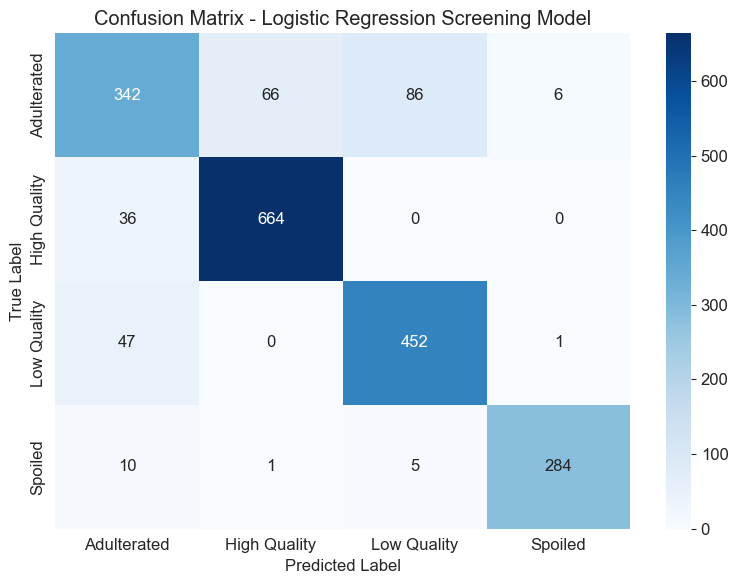

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Confusion Matrix - Logistic Regression Screening Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=300)
plt.show()

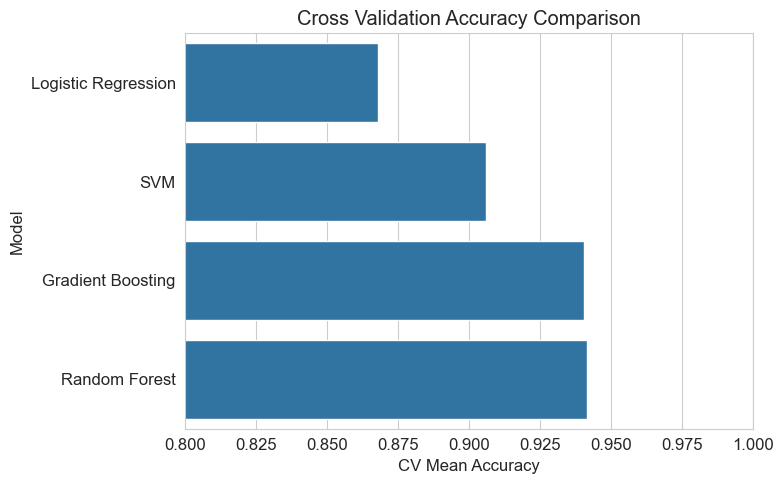

In [20]:
plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x="CV Mean Accuracy", y="Model")
plt.title("Cross Validation Accuracy Comparison")
plt.xlim(0.80, 1.00)
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", dpi=300)
plt.show()

In [21]:
joblib.dump(best_pipeline, "models/milk_quality_pipeline.joblib")
joblib.dump(label_encoder, "models/label_encoder.joblib")

metrics = {
    "best_model": best_model_name,
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "feature_set_used": screening_features,
    "excluded_features": [
        "Water_Adulteration_Percent",
        "Urea",
        "Detergent",
        "Starch",
        "Neutralizers",
        "Preservatives",
        "Antibiotics"
    ],
    "cross_validation_results": results_df.to_dict(orient="records")
}

with open("models/model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Model and metrics saved.")

Model and metrics saved.


In [22]:
print("========== FINAL SUMMARY ==========")
print("Selected Model:", best_model_name)
print("Feature Set Used:", screening_features)
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Precision:", round(test_precision, 4))
print("Test Recall:", round(test_recall, 4))
print("Test F1:", round(test_f1, 4))
print("\nCross Validation Results:")
display(results_df)

========== FINAL SUMMARY ==========
Selected Model: Logistic Regression
Feature Set Used: ['pH', 'Titratable_Acidity', 'Fat_Percentage', 'SNF_Percentage', 'Lactose', 'Protein', 'Density', 'Conductivity', 'Freezing_Point']
Test Accuracy: 0.871
Test Precision: 0.869
Test Recall: 0.871
Test F1: 0.8685

Cross Validation Results:


,Model,CV Mean Accuracy,CV Std
0,Logistic Regression,0.8679,0.008309
1,SVM,0.9059,0.009856
3,Gradient Boosting,0.9405,0.005595
2,Random Forest,0.9416,0.004363


In [24]:
import pandas as pd

# Load pipeline
model = joblib.load("models/milk_quality_pipeline.joblib")

# Extract Logistic Regression model from pipeline
lr_model = model.named_steps['model']  # adjust name if different

# Get coefficients
coefficients = lr_model.coef_[0]

# Feature names
features = [
    "pH", "Titratable_Acidity", "Fat_Percentage", "SNF_Percentage",
    "Lactose", "Protein", "Density", "Conductivity", "Freezing_Point"
]

# Create table
coef_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefficients
})

print(coef_df)

              Feature  Coefficient
0                  pH     0.780618
1  Titratable_Acidity    -1.736402
2      Fat_Percentage     0.684102
3      SNF_Percentage    -0.328285
4             Lactose    -0.046779
5             Protein    -0.034920
6             Density    -0.048294
7        Conductivity    -0.030311
8      Freezing_Point    -0.029644
